<a href="https://colab.research.google.com/github/AahanKumar524/A.Kumar/blob/main/Vision_Transformer_Project_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Building a Vision Transformer from Scratch
AI Bootcamp — Project Notebook

## Make a copy of this notebook! Editing directly will not be saved.

In this project you will build a **Vision Transformer (ViT)** — the architecture behind many of today's most powerful image models — entirely from scratch in PyTorch. No pre-built attention layers, no shortcuts: by the end, every important line of the model will be code **you** wrote.

Along the way you will:

1. Build a synthetic image dataset where the answer depends on **comparing two far-apart regions** of the image
2. Build and train a small **convolutional neural network (CNN)** and watch it fail
3. Build a Vision Transformer piece by piece: **patch embeddings → self-attention → multi-head attention → transformer blocks → full model**
4. Train the ViT, beat the CNN, and **visualize what the model is attending to**

**How this notebook works:** this is a self-guided project. Most code cells contain a `# TODO` describing what to write, followed by a `YOUR CODE HERE` block for you to fill in. After most components there is a ✅ **checkpoint cell** with `assert` statements — run it to verify your implementation before moving on. If a checkpoint passes silently (or prints a success message), you're good. If it throws an error, read the error message: it usually tells you which shape or value is wrong.

**Prerequisites:** comfort with Python (functions, classes, loops) and the basics of PyTorch and neural networks (tensors, `nn.Module`, training loops) from the intro notebook. The math uses nothing beyond dot products, averages, and the exponential function.

> ⏱️ **Runtime tip:** training takes ~1 minute per model on a GPU and ~5 minutes on a CPU. On Google Colab, go to `Runtime → Change runtime type → T4 GPU` before you start.

In [1]:
## Standard libraries
import math
import numpy as np

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline

## Progress bar
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data

print("Using torch", torch.__version__)

Using torch 2.14.1+cu130


In [2]:
# Reproducibility: setting seeds means the "random" numbers come out the same every run
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print("Device:", device)

Device: cuda


## 1. Background: Why Transformers for Images?

### The problem with looking locally

A convolutional neural network looks at an image through a stack of small filters (typically $3\times3$ pixels). Each layer can only combine information from a small neighborhood around each pixel. Stacking layers grows this neighborhood — the region of the input that can influence a given output is called the **receptive field** — but it grows *slowly*, and pooling layers that shrink the image throw information away along the way.

That's perfectly fine for questions like *"is there a cat ear texture here?"*. It is much worse for questions like *"is the object in the top-left corner **the same** as the object in the bottom-right corner?"* — a question about the **relationship between distant parts of the image**.

### The transformer idea

In 2017, the paper [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762) introduced the **transformer**, built around a mechanism called **self-attention**. Instead of each position only seeing its neighbors, *every* position can directly look at *every other* position — in a single layer. The model *learns* which positions are worth looking at.

Transformers took over language modeling (every sentence is a sequence of word tokens), and in 2020 the [Vision Transformer paper](https://arxiv.org/abs/2010.11929) showed the same trick works on images with one simple move:

> **Cut the image into small square patches, treat each patch like a "word", and feed the sequence of patches into a standard transformer.**

That's the entire model you're going to build. Schematically:

```
image → split into patches → linear embedding (+ position info)
      → [ transformer block ] × N
      → classification head → prediction
```

### Our experiment

To see *when* attention actually wins, we'll design a task that is **all about long-range relationships** — and pit a CNN against your ViT in a fair fight.

## 2. The Task: "Twin Patterns"

Each image is a $48\times48$ grayscale picture containing exactly **two small $6\times6$ pixel patterns** dropped at random locations on a black background.

* **Class 1 ("twins"):** the two patterns are **pixel-for-pixel identical**
* **Class 0 ("strangers"):** the two patterns are **different** random patterns

To classify an image you must (1) find both patterns, wherever they are, and (2) **compare them to each other** — possibly across the entire width of the image. A texture detector can't answer this. There is no single local clue anywhere in the image; the *only* signal is the relationship between two far-apart regions.

This is exactly the kind of task self-attention is built for — and a famously hard kind of task (called a *same/different* task) for convolutional networks.

To keep the geometry simple, we divide the image into a $6\times6$ grid of $8\times8$ **cells** and drop each pattern into its own randomly chosen cell (so patterns never overlap). Conveniently, this grid will line up with our ViT patches later.

In [3]:
IMG_SIZE = 48   # images are 48x48 pixels
CELL = 8        # the image is divided into 8x8 cells...
GRID = IMG_SIZE // CELL   # ...forming a 6x6 grid of cells (36 cells total)
PAT = 6         # each pattern is 6x6 pixels, centered inside its 8x8 cell

NUM_CLASSES = 2

In [4]:
def random_pattern():
    """Returns a random 6x6 binary pattern (each pixel is 0.0 or 1.0 with 50/50 odds)."""
    p = (torch.rand(PAT, PAT) < 0.5).float()
    if p.sum() == 0:           # all-black patterns would be invisible; extremely unlikely,
        return random_pattern()  # but resample just in case
    return p


def place_pattern(img, cell_idx, pattern):
    """Pastes a 6x6 pattern into cell number `cell_idx` (0..35) of a 1x48x48 image.

    Cells are numbered left-to-right, top-to-bottom:
        cell 0 = top-left, cell 5 = top-right, cell 35 = bottom-right.
    The +1 offset centers the 6x6 pattern inside its 8x8 cell.
    """
    row = (cell_idx // GRID) * CELL + 1
    col = (cell_idx % GRID) * CELL + 1
    img[0, row:row + PAT, col:col + PAT] = pattern

### ✏️ Your turn — build the dataset

Complete the `TwinPatternsDataset` class below. As in the intro notebook, a PyTorch `Dataset` needs `__len__` and `__getitem__`; here we also pre-generate all the images up front in `generate()`.

For each image $i$, `generate()` should:

1. Pick **two different cells** out of the 36 — `torch.randperm(36)[:2]` gives you two distinct random cell indices
2. Create the first pattern with `random_pattern()`
3. If the label is `1`, the second pattern is an exact **copy** of the first (`.clone()`).
   If the label is `0`, sample a **new** random pattern — and keep resampling until it's actually different from the first (`torch.equal(a, b)` tests if two tensors are identical; a `while` loop helps)
4. Place both patterns into the image with `place_pattern(...)`

The random 0/1 labels are created for you.

In [5]:
class TwinPatternsDataset(data.Dataset):

    def __init__(self, size):
        """
        Inputs:
            size - number of images to generate
        """
        super().__init__()
        self.size = size
        self.generate()

    def generate(self):
        # Pre-allocate: `size` grayscale (1-channel) images, all black to start
        self.images = torch.zeros(self.size, 1, IMG_SIZE, IMG_SIZE)
        # Random labels: 0 = strangers, 1 = twins
        self.labels = torch.randint(low=0, high=2, size=(self.size,))

        for i in range(self.size):
            # TODO: follow steps 1-4 from the instructions above to fill in
            #       self.images[i] based on self.labels[i]
            cell_a, cell_b = torch.randperm(GRID * GRID)[:2]

            pattern_a = random_pattern()
            if self.labels[i] == 1:
                pattern_b = pattern_a.clone()
            else:
                pattern_b = random_pattern()
                while torch.equal(pattern_a, pattern_b):
                    pattern_b = random_pattern()

            place_pattern(self.images[i], cell_a, pattern_a)
            place_pattern(self.images[i], cell_b, pattern_b)
            # END TODO

    def __len__(self):
        # TODO: return the number of images in the dataset
        return self.size
        # END TODO

    def __getitem__(self, idx):
        # TODO: return the idx-th (image, label) pair as a tuple
        return self.images[idx], self.labels[idx]
        # END TODO

In [6]:
# ✅ CHECKPOINT — run this cell to verify your dataset
_check = TwinPatternsDataset(size=200)

assert len(_check) == 200, "__len__ should return the dataset size"
img0, label0 = _check[0]
assert img0.shape == (1, IMG_SIZE, IMG_SIZE), f"images should be (1, 48, 48), got {tuple(img0.shape)}"
assert set(_check.labels.tolist()) == {0, 1}, "labels should contain both 0s and 1s"

def _occupied_cells(img):
    """Returns the contents of every non-empty cell in an image."""
    found = []
    for c in range(GRID * GRID):
        r, col = (c // GRID) * CELL, (c % GRID) * CELL
        cell = img[0, r:r + CELL, col:col + CELL]
        if cell.sum() > 0:
            found.append(cell)
    return found

for i in range(200):
    cells_found = _occupied_cells(_check.images[i])
    assert len(cells_found) == 2, f"image {i} has {len(cells_found)} patterns; expected exactly 2"
    same = torch.equal(cells_found[0], cells_found[1])
    assert same == bool(_check.labels[i]), \
        f"image {i}: patterns {'match' if same else 'differ'} but label is {_check.labels[i].item()}"

print("All checks passed! 🎉 Your dataset works.")

All checks passed! 🎉 Your dataset works.


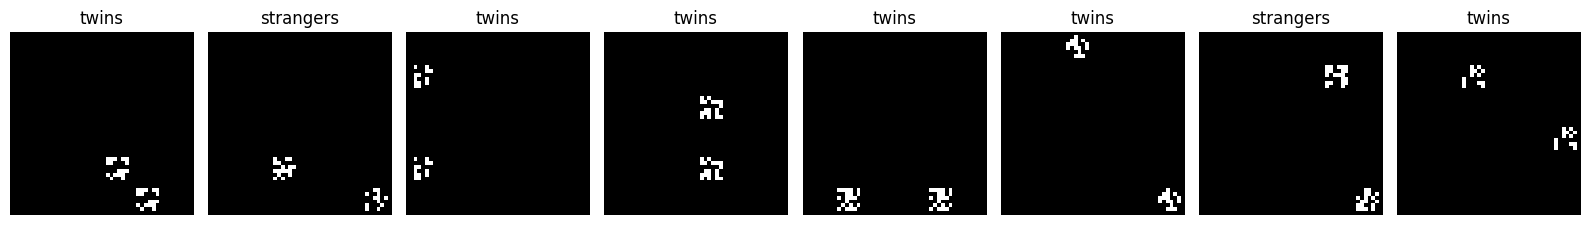

In [7]:
# Let's look at some samples (visualization code provided)
def show_samples(dataset, n=8):
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for ax in axes:
        idx = np.random.randint(len(dataset))
        img, label = dataset[idx]
        ax.imshow(img[0], cmap="gray")
        ax.set_title("twins" if label == 1 else "strangers")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(_check)

Look closely at a few "twins" vs "strangers" images. Could *you* classify these at a glance? Notice that you naturally **look back and forth between the two patterns** to compare them — that is exactly the computation we want our model to learn.

Now generate the real training and test sets:

In [8]:
train_dataset = TwinPatternsDataset(size=6000)
test_dataset  = TwinPatternsDataset(size=1000)

train_loader = data.DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = data.DataLoader(test_dataset, batch_size=256, shuffle=False, drop_last=False)

print("Train size:", len(train_dataset), "| Test size:", len(test_dataset))

Train size: 6000 | Test size: 1000


## 3. The Challenger: a Convolutional Neural Network

Before building the transformer, we need a baseline. We'll use a standard small CNN: three rounds of *(convolution → ReLU → max-pool)*, then **global average pooling** (average each feature map down to one number) and a linear classification layer.

A quick reference for the two building blocks (you saw `nn.Linear` in the intro notebook; these are the image equivalents):

* `nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)` — slides `out_channels` learned $3\times3$ filters over the image. `padding=1` keeps the height/width unchanged.
* `nn.MaxPool2d(2)` — halves the height and width by keeping the max of each $2\times2$ block.

### ✏️ Your turn — build the CNN

Build this architecture (input is `[B, 1, 48, 48]`, where `B` is the batch size):

| Layer | Spec | Output shape |
|---|---|---|
| Conv → ReLU → MaxPool | 1 → 32 channels, $3\times3$, padding 1 | `[B, 32, 24, 24]` |
| Conv → ReLU → MaxPool | 32 → 64 channels, $3\times3$, padding 1 | `[B, 64, 12, 12]` |
| Conv → ReLU → MaxPool | 64 → 64 channels, $3\times3$, padding 1 | `[B, 64, 6, 6]` |
| Global average pool | mean over the two spatial dimensions | `[B, 64]` |
| Linear | 64 → 2 classes | `[B, 2]` |

*Hints:* an `nn.Sequential(...)` is a tidy way to stack the conv layers. For global average pooling, `x.mean(dim=(2, 3))` averages dimensions 2 and 3 (height and width) of a `[B, C, H, W]` tensor.

In [9]:
class SmallCNN(nn.Module):

    def __init__(self):
        super().__init__()
        # TODO: define the layers from the table above
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.head = nn.Linear(64, NUM_CLASSES)
        # END TODO

    def forward(self, x):
        # TODO: conv layers -> global average pool -> linear head
        x = self.conv_layers(x)
        x = x.mean(dim=(2, 3))   # global average pooling: [B, 64, 6, 6] -> [B, 64]
        return self.head(x)
        # END TODO

In [10]:
# ✅ CHECKPOINT — shapes and parameter count
cnn = SmallCNN()
_out = cnn(torch.zeros(4, 1, IMG_SIZE, IMG_SIZE))
assert _out.shape == (4, NUM_CLASSES), f"expected output shape (4, 2), got {tuple(_out.shape)}"

cnn_params = sum(p.numel() for p in cnn.parameters())
print(f"Output shape OK. The CNN has {cnn_params:,} trainable parameters.")

Output shape OK. The CNN has 55,874 trainable parameters.


### 🤔 Think about it: the receptive field

Each $3\times3$ convolution lets a pixel "see" 1 pixel further in every direction; each max-pool *doubles* how far subsequent layers reach in the original image. If you work it out for our CNN, one number in the final $6\times6$ feature map sees roughly a $22\times22$ pixel window of the input.

Our two patterns can be up to ~40 pixels apart. So **no single neuron before the global pooling step ever sees both patterns at once.** The only place all the information meets is the final average — and averaging destroys *where* and *what* each pattern was. Keep this in mind for when we look at the results.

## 4. Training and Evaluation Functions

We'll train both models with the exact same code, so the comparison is fair. This is the same 5-step loop from the intro notebook:

1. Move the batch to the `device`
2. Run the model on the inputs to get predictions
3. Compute the loss
4. Backpropagate (`zero_grad` → `backward`)
5. Update the parameters (`step`)

**One change from the intro notebook:** there we did *binary* classification with one output neuron and `BCEWithLogitsLoss`. Here we use the more general setup that works for any number of classes: the model outputs **one score per class** (2 scores), we use `nn.CrossEntropyLoss()` as the loss, and the predicted class is the index of the highest score — `scores.argmax(dim=1)`.

### ✏️ Your turn — `eval_model` and `train_model`

In [11]:
def eval_model(model, data_loader):
    """Returns the model's accuracy (a float between 0 and 1) on a data loader."""
    model.eval()  # set model to evaluation mode
    correct, total = 0.0, 0.0

    with torch.no_grad():  # no gradients needed for evaluation
        for imgs, labels in data_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            # TODO: get the model's scores, take argmax over the class dimension
            #       to get predicted labels, and update `correct` and `total`.
            #       Hint: (pred_labels == labels).sum() counts correct predictions.
            scores = model(imgs)
            pred_labels = scores.argmax(dim=1)
            correct += (pred_labels == labels).sum().item()
            total += labels.shape[0]
            # END TODO

    return correct / total

In [12]:
def train_model(model, train_loader, test_loader, num_epochs=10, lr=1e-3):
    """Trains the model and returns a list of test accuracies (one per epoch)."""
    model.to(device)

    # TODO: create an Adam optimizer over model.parameters() with learning rate lr,
    #       and a CrossEntropyLoss module
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_module = nn.CrossEntropyLoss()
    # END TODO

    acc_history = []
    for epoch in tqdm(range(num_epochs)):
        model.train()  # set model to training mode
        epoch_loss = 0.0

        for imgs, labels in train_loader:
            # TODO: the 5 training steps (move data to device, predict,
            #       compute loss, zero_grad + backward, optimizer step).
            #       Also add loss.item() to epoch_loss so we can print it.
            imgs, labels = imgs.to(device), labels.to(device)

            preds = model(imgs)
            loss = loss_module(preds, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            # END TODO

        test_acc = eval_model(model, test_loader)
        acc_history.append(test_acc)
        print(f"Epoch {epoch + 1:2d} | avg loss {epoch_loss / len(train_loader):.3f} | test acc {100 * test_acc:5.1f}%")

    return acc_history

## 5. Round 1: Train the CNN

Time for the baseline's shot at the title. (~1 min on GPU, a few minutes on CPU.)

In [13]:
torch.manual_seed(7)
cnn = SmallCNN()
cnn_history = train_model(cnn, train_loader, test_loader, num_epochs=10)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch  1 | avg loss 0.694 | test acc  51.3%
Epoch  2 | avg loss 0.693 | test acc  51.3%
Epoch  3 | avg loss 0.693 | test acc  51.3%
Epoch  4 | avg loss 0.693 | test acc  51.3%
Epoch  5 | avg loss 0.693 | test acc  51.2%
Epoch  6 | avg loss 0.693 | test acc  51.3%
Epoch  7 | avg loss 0.693 | test acc  51.3%
Epoch  8 | avg loss 0.693 | test acc  50.7%
Epoch  9 | avg loss 0.693 | test acc  51.3%
Epoch 10 | avg loss 0.693 | test acc  49.1%


### 😬 What just happened?

You should see the CNN's loss frozen around $0.693$ and its accuracy stuck at ~50% — **a coin flip**. It's not a bug. (Fun check: $-\ln(0.5) \approx 0.693$ — that's exactly the cross-entropy loss of a model that's 50/50 on every image. The CNN has learned to shrug.)

Why? Remember the receptive field discussion: no neuron ever sees both patterns, and global averaging scrambles together *what the patterns look like* and *where they are* into one position-less summary. The information needed to *compare* the two patterns is simply gone by the time it reaches the classifier. The CNN isn't too small or undertrained — it's the wrong *shape of computation* for this task.

What we need is an architecture where information from one part of the image can be **directly compared** with another part, no matter the distance. Enter self-attention.

## 6. Building the Vision Transformer

We'll build the ViT bottom-up, checking shapes at every step:

```
6.1 Patch embedding        image -> sequence of patch vectors
6.2 Self-attention         the heart of the transformer
6.3 Multi-head attention   several attentions in parallel
6.4 Transformer block      attention + MLP, with residual connections
6.5 The full ViT           CLS token, positions, blocks, classifier
```

Throughout, our tensors will have shape `[B, N, D]`: a **B**atch of sequences, each with **N** tokens, each token a vector of **D** numbers.

### 6.1 Patch Embedding

Step one: turn a `[B, 1, 48, 48]` image into a *sequence* of patch vectors. With a patch size of $8$, a $48\times48$ image becomes a $6\times6$ grid of patches → a sequence of $N = 36$ tokens. Each $8\times8$ patch (64 pixel values) gets mapped to a learned $D$-dimensional **embedding vector** — the patch's "meaning", just like a word embedding in a language model.

Here's a neat trick to do both steps (cutting + embedding) at once:

> `nn.Conv2d(1, embed_dim, kernel_size=patch_size, stride=patch_size)`

Because the kernel is exactly one patch wide and the stride jumps a full patch each step, the windows **never overlap**: the convolution lands on each patch exactly once and outputs one $D$-dimensional vector per patch. It's not really "convolving" at all — it's just applying the same linear layer to each patch independently.

The output of that conv has shape `[B, D, 6, 6]`. We then flatten the $6\times6$ grid into a sequence of 36 and move dimensions around to get `[B, 36, D]` — that reshaping line is provided.

In [14]:
class PatchEmbedding(nn.Module):

    def __init__(self, patch_size, embed_dim):
        super().__init__()
        # TODO: define self.proj, the Conv2d described above
        #       (in_channels=1 since our images are grayscale)
        self.proj = nn.Conv2d(1, embed_dim, kernel_size=patch_size, stride=patch_size)
        # END TODO

    def forward(self, x):
        # TODO: apply self.proj to x      -> shape [B, D, 6, 6]
        x = self.proj(x)
        # END TODO
        x = x.flatten(2)         # flatten the 6x6 grid:    [B, D, 6, 6] -> [B, D, 36]
        x = x.transpose(1, 2)    # swap dims 1 and 2:       [B, D, 36]   -> [B, 36, D]
        return x

In [15]:
# ✅ CHECKPOINT
_pe = PatchEmbedding(patch_size=8, embed_dim=64)
_out = _pe(torch.zeros(4, 1, 48, 48))
assert _out.shape == (4, 36, 64), f"expected (4, 36, 64), got {tuple(_out.shape)}"
print("Patch embedding OK: image -> sequence of 36 tokens of dimension 64 🎉")

Patch embedding OK: image -> sequence of 36 tokens of dimension 64 🎉


### 6.2 Self-Attention — the Heart of the Transformer

Here's the big idea. Each token (patch) gets to **ask a question** and **gather an answer from every other token**. Concretely, from each token's vector we compute three new vectors with three learned linear layers:

* a **query** $q$ — *"what am I looking for?"*
* a **key** $k$ — *"what do I contain?"*
* a **value** $v$ — *"what information do I pass along if someone attends to me?"*

**How much should token $i$ pay attention to token $j$?** We measure how well $i$'s query matches $j$'s key using the **dot product** $q_i \cdot k_j$ — recall that the dot product is large when two vectors point in similar directions. Stacking all tokens into matrices $Q, K, V$ (each of shape $N \times d$), all $N^2$ scores at once are:

$$\text{scores} = \frac{QK^{\top}}{\sqrt{d}} \qquad (N \times N \text{ matrix})$$

The $\sqrt{d}$ keeps the scores from blowing up as vectors get longer (a dot product of $d$-dimensional vectors is a sum of $d$ terms, and its typical size grows like $\sqrt{d}$ — dividing by $\sqrt{d}$ cancels that).

**Turning scores into weights.** Each row of scores is passed through a **softmax**, which converts any list of numbers $s_1, \dots, s_N$ into positive weights that sum to 1:

$$\text{softmax}(s)_j = \frac{e^{s_j}}{\sum_{m} e^{s_m}}$$

Big scores → weights near 1; small scores → weights near 0. It's a "soft" version of picking the maximum.

**Gathering the answer.** Each token's output is the **weighted average of all the value vectors**, using its row of attention weights:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d}}\right) V$$

That single line is the famous attention formula. Note what it gives us: token 7 can put 90% of its weight on token 31 **on the other side of the image** in the very first layer. No receptive field to grow, no pooling — direct comparison at any distance.

### ✏️ Your turn — attention on raw tensors

Before wrapping it in a class, implement the formula once on plain tensors. Useful ops:

* `A @ B` — matrix multiplication
* `K.transpose(-2, -1)` — swap the last two dimensions (this is $K^\top$, done batch-wise)
* `scores.softmax(dim=-1)` — softmax along the last dimension, i.e. across each **row**
* `math.sqrt(d)`

In [16]:
def attention(Q, K, V):
    """Scaled dot-product attention.

    Inputs:  Q, K, V of shape [B, N, d]
    Returns: (output, attn_weights) where
             output has shape [B, N, d] and attn_weights has shape [B, N, N]
    """
    d = Q.shape[-1]
    # TODO: implement the attention formula in three small steps:
    #   1. scores = Q @ K^T, divided by sqrt(d)        -> [B, N, N]
    #   2. attn_weights = softmax over the last dim     -> [B, N, N]
    #   3. output = attn_weights @ V                    -> [B, N, d]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d)
    attn_weights = scores.softmax(dim=-1)
    output = attn_weights @ V
    # END TODO
    return output, attn_weights

In [17]:
# ✅ CHECKPOINT
_Q = torch.randn(2, 5, 16); _K = torch.randn(2, 5, 16); _V = torch.randn(2, 5, 16)
_out, _w = attention(_Q, _K, _V)

assert _out.shape == (2, 5, 16), f"output shape should be (2, 5, 16), got {tuple(_out.shape)}"
assert _w.shape == (2, 5, 5), f"attention weights should be (2, 5, 5), got {tuple(_w.shape)}"
assert torch.allclose(_w.sum(dim=-1), torch.ones(2, 5)), "each row of attention weights must sum to 1"
assert (_w >= 0).all(), "attention weights must be non-negative"

# If every key is identical, every token should attend equally (weights = 1/N) and
# the output should equal the average of the values:
_K_same = torch.ones(1, 4, 16)
_out2, _w2 = attention(torch.randn(1, 4, 16), _K_same, _V[:1, :4])
assert torch.allclose(_w2, torch.full((1, 4, 4), 0.25), atol=1e-5), \
    "with identical keys, all attention weights should be 1/N"
print("Attention works! 🎉")

Attention works! 🎉


### 6.3 Multi-Head Attention

One attention layer computes *one* pattern of "who looks at whom". But we might want several at once — e.g. one head that compares pattern shapes, another that tracks positions. **Multi-head attention** splits the $D$-dimensional vectors into `num_heads` smaller chunks (each of size $d_{head} = D / \text{num\_heads}$), runs your `attention` function on each chunk **independently and in parallel**, then concatenates the results and mixes them with one final linear layer.

The dimension-juggling that splits `[B, N, D]` into `[B, num_heads, N, d_head]` (and back) is fiddly and not very enlightening, so the helpers `split_heads` and `merge_heads` are **provided**. Your `attention` function already works on these shapes without modification — it treats the leading dimensions as "batch", so `[B, H, N, d_head]` works just as well as `[B, N, d]`. The interesting part — projections and attention — is yours.

One extra detail: we save the attention weights into `self.last_attn` each forward pass, so that after training we can **visualize where the model looks**.

In [18]:
class MultiHeadSelfAttention(nn.Module):

    def __init__(self, embed_dim, num_heads):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # TODO: define four linear layers, each mapping embed_dim -> embed_dim:
        #       self.q_proj, self.k_proj, self.v_proj  (compute queries/keys/values)
        #       self.out_proj                          (mixes the heads at the end)
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        # END TODO

        self.last_attn = None  # we'll stash attention weights here for visualization

    # ---- provided helpers (fiddly reshaping, nothing conceptual) ----
    def split_heads(self, x):
        """[B, N, D] -> [B, num_heads, N, head_dim]"""
        B, N, D = x.shape
        return x.reshape(B, N, self.num_heads, self.head_dim).transpose(1, 2)

    def merge_heads(self, x):
        """[B, num_heads, N, head_dim] -> [B, N, D]"""
        B, H, N, dh = x.shape
        return x.transpose(1, 2).reshape(B, N, H * dh)
    # -----------------------------------------------------------------

    def forward(self, x):
        # TODO:
        #   1. Compute Q, K, V by applying the three projections to x, and
        #      split each into heads                        -> [B, H, N, head_dim]
        #   2. Run your attention() function on Q, K, V
        #   3. Save the attention weights: self.last_attn = attn_weights.detach()
        #   4. Merge the heads back together                -> [B, N, D]
        #   5. Apply the output projection and return
        Q = self.split_heads(self.q_proj(x))
        K = self.split_heads(self.k_proj(x))
        V = self.split_heads(self.v_proj(x))

        out, attn_weights = attention(Q, K, V)
        self.last_attn = attn_weights.detach()

        out = self.merge_heads(out)
        return self.out_proj(out)
        # END TODO

In [19]:
# ✅ CHECKPOINT
_mha = MultiHeadSelfAttention(embed_dim=64, num_heads=4)
_out = _mha(torch.randn(2, 37, 64))
assert _out.shape == (2, 37, 64), f"expected (2, 37, 64), got {tuple(_out.shape)}"
assert _mha.last_attn is not None, "remember to save self.last_attn"
assert _mha.last_attn.shape == (2, 4, 37, 37), \
    f"last_attn should be (2, 4, 37, 37) (one NxN map per head), got {tuple(_mha.last_attn.shape)}"
print("Multi-head attention OK! 🎉")

Multi-head attention OK! 🎉


### 6.4 The Transformer Block

A transformer is just this block, stacked $N$ times:

```
x ──→ LayerNorm ──→ Multi-Head Attention ──→ (+) ──→ LayerNorm ──→ MLP ──→ (+) ──→ out
│                                             ↑  │                          ↑
└───────────────── skip ──────────────────────┘  └────────── skip ──────────┘
```

In code, that picture is just two lines:

$$x \leftarrow x + \text{Attention}(\text{LayerNorm}(x)) \qquad\quad x \leftarrow x + \text{MLP}(\text{LayerNorm}(x))$$

Two ingredients you haven't met yet — both are stabilizers, not new ideas:

* **`nn.LayerNorm(D)`** rescales each token's vector to have mean 0 and spread 1 (then lets the network learn to re-scale). It keeps the numbers in a healthy range as we stack many layers.
* **Residual ("skip") connections** — the `x + ...` parts. Each sub-layer computes a *correction* added onto its input rather than a replacement of it. Gradients can flow straight through the `+`, which makes deep stacks much easier to train. (You saw vanishing gradients with sigmoid in the intro notebook — skip connections are one of the great fixes.)

* The **MLP** is a plain two-layer network applied to each token independently: `Linear(D → mlp_dim) → GELU → Linear(mlp_dim → D)`. (`nn.GELU()` is a smooth cousin of ReLU — the standard choice in transformers.) Attention lets tokens *talk to each other*; the MLP lets each token *think about what it heard*.

### ✏️ Your turn — the block

In [20]:
class TransformerBlock(nn.Module):

    def __init__(self, embed_dim, num_heads, mlp_dim):
        super().__init__()
        # TODO: define
        #   self.norm1 - LayerNorm over embed_dim
        #   self.attn  - your MultiHeadSelfAttention
        #   self.norm2 - another LayerNorm
        #   self.mlp   - Sequential(Linear(embed_dim, mlp_dim), GELU, Linear(mlp_dim, embed_dim))
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, embed_dim),
        )
        # END TODO

    def forward(self, x):
        # TODO: implement the two residual updates:
        #   x = x + attention(norm1(x))
        #   x = x + mlp(norm2(x))
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x
        # END TODO

In [21]:
# ✅ CHECKPOINT
_blk = TransformerBlock(embed_dim=64, num_heads=4, mlp_dim=128)
_x = torch.randn(2, 37, 64)
_out = _blk(_x)
assert _out.shape == (2, 37, 64), f"expected (2, 37, 64), got {tuple(_out.shape)}"
assert not torch.allclose(_out, _x), "the block should actually transform its input"
print("Transformer block OK! 🎉")

Transformer block OK! 🎉


### 6.5 Assembling the Full ViT

Two last ingredients, then we bolt everything together.

**Positional embeddings.** Here's a subtle problem: attention is a weighted average over *all* tokens — nothing in the formula knows token 3 is *next to* token 4, or that token 0 is the top-left patch. Shuffle the tokens and you'd get the same (shuffled) answer! The fix is simple: create a learnable vector for each position and **add** it to the patch embeddings. The model learns its own way to encode "I'm the top-left patch" into each token. In code, a learnable tensor is just `nn.Parameter(...)` — like the tensors with `requires_grad=True` you met in the intro notebook, registered so the optimizer trains it.

**The CLS token.** After the transformer blocks we have 36 token vectors — which one do we classify from? The classic trick: prepend one extra *learnable* token (the "classification token") to every sequence. It carries no image content of its own; over the layers, it attends to the patches and **collects a summary of the whole image**. At the end, we classify using the CLS token's final vector alone. (36 patches + 1 CLS = 37 tokens — that's where the 37s in the checkpoints came from!)

The full forward pass:

1. `patch_embed(x)` → `[B, 36, D]`
2. Prepend the CLS token → `[B, 37, D]` — hints: `self.cls_token.expand(B, -1, -1)` makes `B` copies, and `torch.cat([cls, x], dim=1)` glues them along the token dimension
3. Add the positional embeddings (broadcasting handles the batch dimension)
4. Pass through the transformer blocks, then the final LayerNorm
5. Take the CLS token's vector — `x[:, 0]` — and apply the classification head

### ✏️ Your turn — the Vision Transformer

In [22]:
class ViT(nn.Module):

    def __init__(self, img_size=48, patch_size=8, embed_dim=64,
                 depth=3, num_heads=4, mlp_dim=128, num_classes=2):
        super().__init__()
        num_patches = (img_size // patch_size) ** 2   # 36 for us

        # TODO: define
        #   self.patch_embed - your PatchEmbedding
        #   self.cls_token   - nn.Parameter(torch.zeros(1, 1, embed_dim))
        #   self.pos_embed   - nn.Parameter(0.02 * torch.randn(1, num_patches + 1, embed_dim))
        #   self.blocks      - nn.Sequential of `depth` TransformerBlocks
        #   self.norm        - final LayerNorm
        #   self.head        - Linear(embed_dim, num_classes)
        self.patch_embed = PatchEmbedding(patch_size, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(0.02 * torch.randn(1, num_patches + 1, embed_dim))
        self.blocks = nn.Sequential(
            *[TransformerBlock(embed_dim, num_heads, mlp_dim) for _ in range(depth)]
        )
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)
        # END TODO

    def forward(self, x):
        B = x.shape[0]
        # TODO: implement forward-pass steps 1-5 from the instructions above
        x = self.patch_embed(x)                          # [B, 36, D]
        cls = self.cls_token.expand(B, -1, -1)           # [B, 1, D]
        x = torch.cat([cls, x], dim=1)                   # [B, 37, D]
        x = x + self.pos_embed                           # add position info
        x = self.blocks(x)                               # transformer blocks
        x = self.norm(x)                                 # final LayerNorm
        return self.head(x[:, 0])                        # classify from the CLS token
        # END TODO

In [23]:
# ✅ CHECKPOINT
vit = ViT()
_out = vit(torch.zeros(4, 1, IMG_SIZE, IMG_SIZE))
assert _out.shape == (4, NUM_CLASSES), f"expected (4, 2), got {tuple(_out.shape)}"

vit_params = sum(p.numel() for p in vit.parameters())
print(f"ViT forward pass OK 🎉")
print(f"ViT parameters: {vit_params:,}  |  CNN parameters: {cnn_params:,}")

ViT forward pass OK 🎉
ViT parameters: 107,266  |  CNN parameters: 55,874


You just built a Vision Transformer from scratch. Every piece of the modern transformer recipe — QKV attention, multiple heads, residual connections, LayerNorm, CLS token, positional embeddings — is in your code. (The big models behind today's AI systems are, at their core, this same block stacked ~100 times with vectors ~100× wider.)

## 7. Round 2: Train the ViT

Same data, same training function, same number of epochs.

> 🧘 **Be patient for the first few epochs!** Transformers often spend a while looking just as stuck as the CNN (loss ≈ 0.693, accuracy ≈ 50%) — and then the loss suddenly drops off a cliff once attention discovers the comparison strategy. If you're still at 50% after epoch 7 or so, re-check your attention implementation; otherwise, enjoy the moment it "clicks".

In [24]:
torch.manual_seed(7)
vit = ViT()
vit_history = train_model(vit, train_loader, test_loader, num_epochs=10)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch  1 | avg loss 0.724 | test acc  51.3%
Epoch  2 | avg loss 0.694 | test acc  51.3%
Epoch  3 | avg loss 0.694 | test acc  51.3%
Epoch  4 | avg loss 0.692 | test acc  58.3%
Epoch  5 | avg loss 0.590 | test acc  85.8%
Epoch  6 | avg loss 0.262 | test acc  96.5%
Epoch  7 | avg loss 0.073 | test acc  97.6%
Epoch  8 | avg loss 0.040 | test acc  98.4%
Epoch  9 | avg loss 0.030 | test acc  97.6%
Epoch 10 | avg loss 0.013 | test acc  98.3%


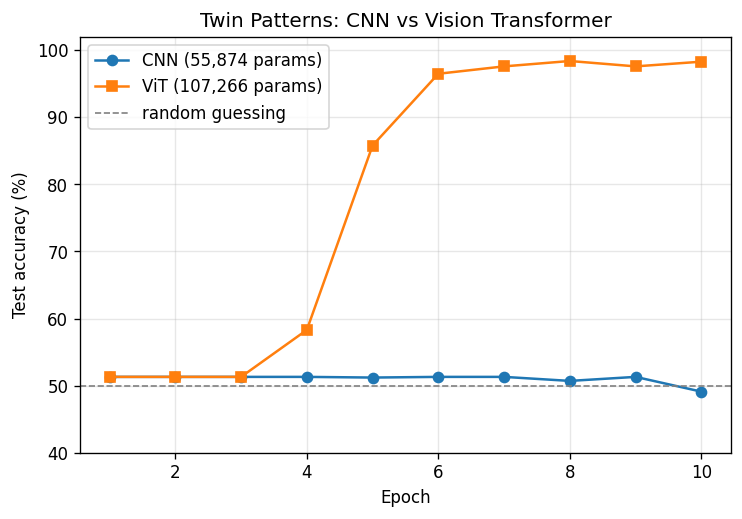

Final test accuracy — CNN: 49.1%   ViT: 98.3%


In [25]:
# Compare the two models (plotting code provided)
plt.figure(figsize=(7, 4.5), dpi=120)
epochs = np.arange(1, len(cnn_history) + 1)
plt.plot(epochs, 100 * np.array(cnn_history), "o-", label=f"CNN ({cnn_params:,} params)")
plt.plot(epochs, 100 * np.array(vit_history), "s-", label=f"ViT ({vit_params:,} params)")
plt.axhline(50, color="gray", ls="--", lw=1, label="random guessing")
plt.xlabel("Epoch"); plt.ylabel("Test accuracy (%)")
plt.title("Twin Patterns: CNN vs Vision Transformer")
plt.ylim(40, 102); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print(f"Final test accuracy — CNN: {100*cnn_history[-1]:.1f}%   ViT: {100*vit_history[-1]:.1f}%")

### 🥊 The verdict

The CNN never leaves the random-guessing line; your ViT should finish around **95–99%**. The difference isn't size (the models are within ~2× of each other in parameter count) or training budget (identical) — it's that self-attention can put two arbitrary patches side by side and compare them in a single step, and a convolution fundamentally cannot.

**Honest fine print 🧐:** this does *not* mean ViTs beat CNNs everywhere. On ordinary photo datasets, CNNs' built-in assumptions (nearby pixels matter most, a cat is a cat anywhere in the frame) are *advantages* — a ViT trained from scratch on a small dataset like CIFAR-10 typically *loses* to a CNN, and big ViTs win only after pretraining on enormous datasets. We deliberately designed a task where global relationships are everything. Knowing *which* architecture fits *which* task is exactly the kind of judgment ML researchers need.

## 8. Looking Inside: What Is the Model Attending To?

A unique perk of transformers: the attention weights are an interpretable, built-in record of *where the model looked*. Remember `self.last_attn`? Each forward pass, every attention layer stored its `[B, heads, 37, 37]` weight matrix.

Row 0 of that matrix is the **CLS token's attention**: how much the image-summary token attended to each of the 36 patches (plus itself). If your ViT really learned to compare the two patterns, the CLS token should be focusing on... well, let's see. The visualization code is provided — run it on a few test images.

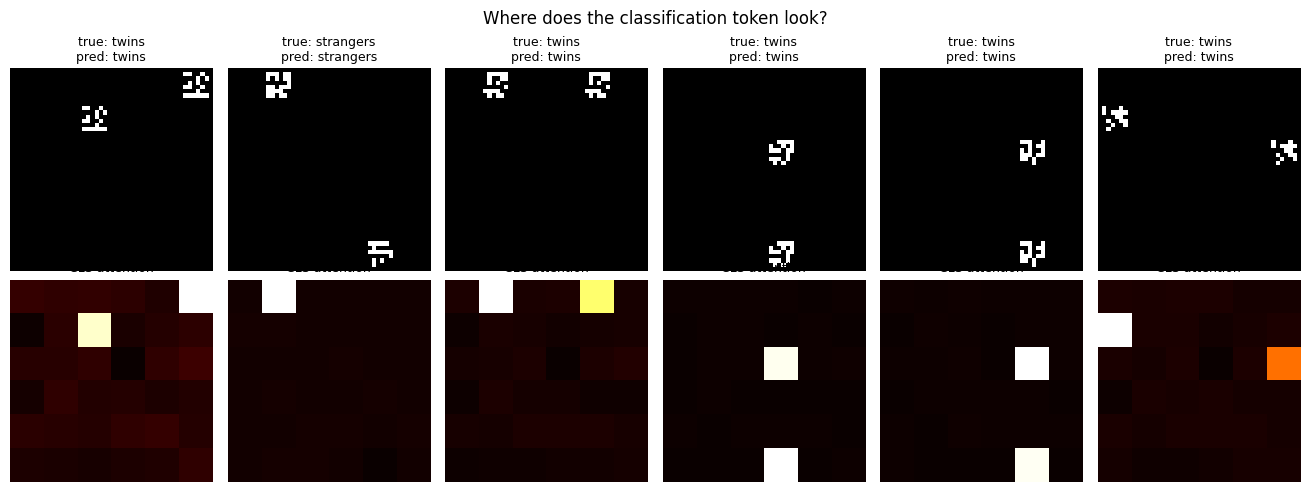

In [26]:
@torch.no_grad()
def show_cls_attention(model, dataset, n=6, block_idx=-1):
    model.eval()
    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 5))
    for j in range(n):
        idx = np.random.randint(len(dataset))
        img, label = dataset[idx]

        pred = model(img.unsqueeze(0).to(device)).argmax(dim=1).item()
        # CLS row of the chosen block's attention, averaged over heads, patches only:
        attn = model.blocks[block_idx].attn.last_attn[0]   # [heads, 37, 37]
        cls_attn = attn[:, 0, 1:].mean(dim=0)              # [36], averaged over heads
        attn_map = cls_attn.reshape(GRID, GRID).cpu()

        axes[0, j].imshow(img[0], cmap="gray")
        axes[0, j].set_title(f"true: {'twins' if label==1 else 'strangers'}\npred: {'twins' if pred==1 else 'strangers'}",
                             fontsize=9)
        axes[1, j].imshow(attn_map, cmap="hot")
        axes[1, j].set_title("CLS attention", fontsize=9)
        for ax in (axes[0, j], axes[1, j]):
            ax.axis("off")
    plt.suptitle("Where does the classification token look?")
    plt.tight_layout()
    plt.show()

show_cls_attention(vit, test_dataset)

### 🤔 Questions to discuss

Run the cell above a few times and look at different images. Then try `block_idx=0` to see the *first* block instead of the last.

1. Which cells light up in the attention maps? Does that match how *you* would solve the task?
2. Does the attention pattern differ between the first block and the last block? Why might early and late layers play different roles?
3. The model was never told the patterns live on an $8\times8$ grid, or that there are exactly two of them. What, exactly, did it have to figure out on its own from labels alone?

## 9. 🚀 Extension Challenges

Done early, or want to take this further? In rough order of difficulty:

1. **Patch size experiments.** Retrain with `patch_size=4` (sequence of 144 tokens) or `patch_size=16`. How do accuracy and training time change? What happens when one pattern gets split across multiple patches?

2. **Break the grid.** Modify the dataset so patterns are placed at *arbitrary* pixel positions (not snapped to cells — just make sure the two patterns don't overlap). Now patterns straddle patch boundaries. How much harder is the task for your ViT? Does a smaller patch size help?

3. **Rescue the CNN.** Can *any* CNN-style change crack this task? Try replacing global average pooling with `nn.Flatten()` + a linear layer, adding more conv layers, or making it much wider. (Spoiler: some versions can inch above 50% by memorizing — check whether they *generalize* by testing on freshly generated data.)

4. **Ablations — which parts actually matter?** Surgery on your own ViT: (a) remove the positional embeddings, (b) use 1 attention head instead of 4, (c) remove the residual connections (`x = self.attn(self.norm1(x))`). Predict the effect *before* each run. Which ablation hurts most? Which surprisingly doesn't? Can you explain why removing positions does/doesn't matter *for this particular task*?

5. **A third class.** Make it 3-way: strangers / twins / *mirror twins* (the second pattern is the first flipped left-right — `torch.flip(p, dims=[1])`). What needs to change in the model? (Hint: almost nothing — that's the point of `NUM_CLASSES`.)

6. **Real images.** Try your ViT on FashionMNIST (loadable via `torchvision.datasets`, as in the intro notebook — you'll need to adjust `img_size` to 28 and pick a patch size that divides it). Compare against the CNN. Given the "honest fine print" above, what do you predict happens — and were you right?

## 10. Recap

You built, from scratch:

* a **synthetic benchmark** that isolates one capability: comparing distant image regions
* a **CNN baseline** — and a concrete understanding (receptive fields, pooling) of *why* it flatlines at 50%
* **scaled dot-product attention**: $\text{softmax}(QK^\top/\sqrt{d})\,V$ — queries, keys, values, and a weighted average
* **multi-head attention**, **transformer blocks** with residual connections and LayerNorm, **positional embeddings**, and a **CLS token**
* a complete **Vision Transformer** that solves the task — and whose attention maps you can read to see *how*

The transformer you wrote today is, structurally, the same architecture powering state-of-the-art language and vision models. The rest is mostly scale. 🎓

In [27]:

#EXTENTSION
# My project was using the CNN and VIT and my own yolov11 model to track the volleyball through a rally


!pip install ultralytics -q

import numpy as np
import torch
from ultralytics import YOLO

tracking_model = YOLO('my_model.pt')

results = tracking_model.track(source='0.0-6.0.mp4', persist=True)

trajectory_points = []

for frame_idx, r in enumerate(results):
    if r.boxes is not None and r.boxes.id is not None:
        boxes = r.boxes.xywh.cpu().numpy()
        track_ids = r.boxes.id.cpu().numpy()

        for box, track_id in zip(boxes, track_ids):
            x, y, w, h = box
            trajectory_points.append({'frame': frame_idx, 'x': x, 'y': y})

print(f"\nCollected {len(trajectory_points)} ball positions from tracking data.")

def make_sliding_windows(data, window_size=10):
    X = []
    coords = np.array([[pt['x'], pt['y']] for pt in data])
    for i in range(len(coords) - window_size + 1):
        X.append(coords[i : i + window_size])
    return np.array(X)

input_windows = make_sliding_windows(trajectory_points, window_size=10)
print("Input matrix shape for your ViT Blocks:", input_windows.shape)



import torch.nn as nn

class TrajectoryEmbedding(nn.Module):
    """Replaces your Image Patch Embedding layer for sequence/tracking coordinates."""
    def __init__(self, input_dim=2, d_model=64):
        super().__init__()
        self.linear = nn.Linear(input_dim, d_model)

    def forward(self, x):
        return self.linear(x)

class VolleyballHitDetectorViT(nn.Module):
    def __init__(self, d_model=64, n_heads=4, num_classes=2):
        super().__init__()
        self.embedding = TrajectoryEmbedding(input_dim=2, d_model=d_model)


        self.transformer_block1 = TransformerBlock(embed_dim=d_model, num_heads=n_heads, mlp_dim=128)
        self.transformer_block2 = TransformerBlock(embed_dim=d_model, num_heads=n_heads, mlp_dim=128)

        self.classification_head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, num_classes)
        )

    def forward(self, x):
        x = self.embedding(x)
        x = self.transformer_block1(x)
        x = self.transformer_block2(x)

        x = x.mean(dim=1)

        return self.classification_head(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

hit_detector_vit = VolleyballHitDetectorViT(d_model=64, n_heads=4).to(device)
print("Extended Volleyball ViT Model Setup Successfully:\n")
print(hit_detector_vit)

if len(input_windows) > 0:
    test_tensor = torch.tensor(input_windows, dtype=torch.float32).to(device)

    hit_detector_vit.eval()
    with torch.no_grad():
        predictions = hit_detector_vit(test_tensor)

    print(f"Tracked the ball for {predictions.shape[0]} frames")
else:
    print("No tracking tracks were gathered. Please confirm 'my_model.pt' and '0.0-6.0.mp4'")










Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


FileNotFoundError: [Errno 2] No such file or directory: 'my_model.pt'